<a href="https://colab.research.google.com/github/saberBenhamda0/Deep_learning_-_Applications_assignments/blob/main/tp2/part2/Part2_MNIST_ViT_From_Scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning Lab — Part 2: Vision Transformer from scratch
**FST Tanger • LSI • Deep Learning • Pr. ELAACHAK LOTFI**  
Student: Saber Ben Hamda

Run in Colab with a GPU. This standalone notebook uses the same seeded MNIST split and evaluation protocol as Part 1. Match `QUICK` and `EPOCHS` across notebooks. Later upload Part 1's `part1_results.csv` and `config.json` for the combined comparison.

The assignment's Medium tutorial could not be fully retrieved during notebook preparation. This is an independent implementation of the standard patch embedding → class token + positional embedding → pre-norm transformer blocks → classifier design, matching the tutorial's topic rather than claiming a line-by-line reproduction. Attention and transformer blocks are implemented explicitly in PyTorch, without a pretrained ViT or `nn.TransformerEncoder`.


In [1]:
import os, json, time, random, copy, gc, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from tqdm.auto import tqdm
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert device.type == 'cuda', 'Select Runtime > Change runtime type > T4 GPU, then rerun.'
print(torch.__version__, torchvision.__version__, torch.cuda.get_device_name(0))
# Quick mode is a balanced, stratified pilot. Use False for the final experiment.
QUICK = False
EPOCHS = 3 if QUICK else 10
N_TRAIN = 6000 if QUICK else 54000
N_VAL = 1000 if QUICK else 6000
OUT = Path('/content/mnist_lab'); OUT.mkdir(exist_ok=True)
raw_train = datasets.MNIST('/content/data', train=True, download=True)
raw_test = datasets.MNIST('/content/data', train=False, download=True)
y_all = np.array(raw_train.targets)
train_ids, val_ids = train_test_split(np.arange(60000), test_size=6000, stratify=y_all, random_state=SEED)
def select(ids, n):
    if n == len(ids): return np.array(ids)
    return train_test_split(ids, train_size=n, stratify=y_all[ids], random_state=SEED)[0]
train_ids, val_ids = select(train_ids,N_TRAIN), select(val_ids,N_VAL)
test_ids = np.arange(10000)  # identical official test set for every model
np.savez(OUT/'split.npz', train=train_ids, val=val_ids, test=test_ids)
class Digits(Dataset):
    def __init__(self, raw, ids, transform): self.raw,self.ids,self.transform=raw,ids,transform
    def __len__(self): return len(self.ids)
    def __getitem__(self,i):
        x,y=self.raw[int(self.ids[i])]
        return self.transform(x), y
def loaders(transform, batch=128):
    return [DataLoader(Digits(raw,ids,transform),batch_size=batch,shuffle=(j==0),num_workers=2,pin_memory=True)
            for j,(raw,ids) in enumerate([(raw_train,train_ids),(raw_train,val_ids),(raw_test,test_ids)])]
def sync(): torch.cuda.synchronize()
criterion=nn.CrossEntropyLoss()
def evaluate(model, loader):
    model.eval(); ys=[]; ps=[]; total=0.; count=0
    with torch.inference_mode():
        for x,y in loader:
            x,y=x.to(device),y.to(device); logits=model(x)
            total+=criterion(logits,y).item()*len(y); count+=len(y)
            ys.extend(y.cpu().tolist()); ps.extend(logits.argmax(1).cpu().tolist())
    return {'accuracy':accuracy_score(ys,ps),'macro_f1':f1_score(ys,ps,labels=list(range(10)),average='macro',zero_division=0),'loss':total/count},ys,ps
def fit(model, name, ls, lr=1e-3):
    model=model.to(device)
    opt=torch.optim.AdamW(filter(lambda p:p.requires_grad,model.parameters()),lr=lr,weight_decay=1e-4)
    history=[]; best=float('inf'); best_state=None
    sync(); started=time.perf_counter()
    for epoch in range(EPOCHS):
        model.train(); total=correct=count=0
        for x,y in tqdm(ls[0],desc=f'{name} {epoch+1}/{EPOCHS}',leave=False):
            x,y=x.to(device),y.to(device); opt.zero_grad(set_to_none=True)
            logits=model(x); loss=criterion(logits,y); loss.backward(); opt.step()
            total+=loss.item()*len(y); correct+=(logits.argmax(1)==y).sum().item(); count+=len(y)
        val,_,_=evaluate(model,ls[1])
        history.append({'epoch':epoch+1,'train_loss':total/count,'train_accuracy':correct/count,'val_loss':val['loss'],'val_accuracy':val['accuracy']})
        print(history[-1])
        if val['loss']<best:
            best=val['loss']; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    sync(); seconds=time.perf_counter()-started
    model.load_state_dict(best_state)
    metrics,ys,ps=evaluate(model,ls[2])
    metrics.update(model=name,training_seconds=seconds,loss_kind='test cross entropy')
    torch.save(best_state,OUT/f'{name}.pt')
    pd.DataFrame(history).to_csv(OUT/f'{name}_history.csv',index=False)
    fig,axs=plt.subplots(1,2,figsize=(10,3))
    h=pd.DataFrame(history); h.plot(x='epoch',y=['train_loss','val_loss'],ax=axs[0]); h.plot(x='epoch',y=['train_accuracy','val_accuracy'],ax=axs[1])
    plt.tight_layout(); plt.savefig(OUT/f'{name}_curves.png'); plt.show()
    ConfusionMatrixDisplay(confusion_matrix(ys,ps,labels=list(range(10)))).plot(); plt.title(name); plt.savefig(OUT/f'{name}_confusion.png'); plt.show()
    print(classification_report(ys,ps,digits=4,zero_division=0))
    return model,metrics
config={'seed':SEED,'quick':QUICK,'epochs':EPOCHS,'train_n':len(train_ids),'val_n':len(val_ids),'test_n':len(test_ids),'gpu':torch.cuda.get_device_name(0),'torch':torch.__version__,'torchvision':torchvision.__version__}
(OUT/'config.json').write_text(json.dumps(config,indent=2))


2.11.0+cu130 0.26.0+cu130 Tesla T4


100%|██████████| 9.91M/9.91M [00:00<00:00, 12.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 343kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.16MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.0MB/s]
/tmp/ipykernel_2711/1315445266.py:28: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  y_all = np.array(raw_train.targets)


187

## 1. Architecture
28×28 images are divided into 49 non-overlapping 4×4 patches. A linear layer projects each 16-value patch to 64 dimensions. Add one learnable class token and 50 positional embeddings. Four encoder blocks use four-head scaled dot-product attention, LayerNorm, residual connections, GELU MLP (width 128), and dropout 0.1. A normalized class token produces 10 logits. AdamW: learning rate 1e-3, weight decay 1e-4.

In [2]:
class Attention(nn.Module):
    def __init__(self,dim=64,heads=4,dropout=.1):
        super().__init__(); assert dim%heads==0
        self.heads=heads; self.d=dim//heads
        self.qkv=nn.Linear(dim,3*dim); self.proj=nn.Linear(dim,dim); self.drop=nn.Dropout(dropout)
    def forward(self,x):
        b,n,c=x.shape
        q,k,v=self.qkv(x).reshape(b,n,3,self.heads,self.d).permute(2,0,3,1,4).unbind(0)
        weights=self.drop(((q@k.transpose(-2,-1))*self.d**-.5).softmax(-1))
        return self.proj((weights@v).transpose(1,2).reshape(b,n,c))
class Block(nn.Module):
    def __init__(self,dim=64,heads=4):
        super().__init__(); self.n1=nn.LayerNorm(dim); self.n2=nn.LayerNorm(dim)
        self.attn=Attention(dim,heads)
        self.mlp=nn.Sequential(nn.Linear(dim,dim*2),nn.GELU(),nn.Dropout(.1),nn.Linear(dim*2,dim),nn.Dropout(.1))
        self.drop=nn.Dropout(.1)
    def forward(self,x):
        x=x+self.drop(self.attn(self.n1(x)))
        return x+self.mlp(self.n2(x))
class ViT(nn.Module):
    def __init__(self,patch=4,dim=64,depth=4,heads=4):
        super().__init__(); self.patch=patch; assert 28%patch==0
        self.embed=nn.Linear(patch*patch,dim)
        self.cls=nn.Parameter(torch.zeros(1,1,dim))
        self.pos=nn.Parameter(torch.randn(1,(28//patch)**2+1,dim)*.02)
        nn.init.normal_(self.cls,std=.02)
        self.blocks=nn.Sequential(*[Block(dim,heads) for _ in range(depth)])
        self.norm=nn.LayerNorm(dim); self.head=nn.Linear(dim,10); self.drop=nn.Dropout(.1)
    def forward(self,x):
        b,c,h,w=x.shape; p=self.patch
        assert c==1 and h==w==28
        # Shape: B, channel, patch-row, patch-col, row-within-patch, col-within-patch.
        patches=x.unfold(2,p,p).unfold(3,p,p).permute(0,2,3,1,4,5).reshape(b,-1,p*p)
        x=self.embed(patches); x=torch.cat([self.cls.expand(b,-1,-1),x],dim=1)
        x=self.blocks(self.drop(x+self.pos))
        return self.head(self.norm(x[:,0]))
model=ViT()
assert model(torch.randn(2,1,28,28)).shape==(2,10)
print('Parameters:',sum(p.numel() for p in model.parameters()))


Parameters: 139018


## 2. Train, evaluate and inspect errors
Training/validation curves, macro-F1, confusion matrix, and classification report are generated. The best validation-loss checkpoint is restored before testing. A short pilot can undertrain a transformer; avoid treating the pilot as the final conclusion.

ViT 1/10:   0%|          | 0/422 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c1fb94d6c00>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7c1fb94d6c00>Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only te

{'epoch': 1, 'train_loss': 1.1305271205725493, 'train_accuracy': 0.5941481481481482, 'val_loss': 0.4735116747220357, 'val_accuracy': 0.8463333333333334}


ViT 2/10:   0%|          | 0/422 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c1fb94d6c00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c1fb94d6c00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

{'epoch': 2, 'train_loss': 0.40293579749707825, 'train_accuracy': 0.8706666666666667, 'val_loss': 0.2370349136988322, 'val_accuracy': 0.9251666666666667}


... (21 outputs left out)

ViT 10/10:   0%|          | 0/422 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c1fb94d6c00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    Exception ignored in: assert self._parent_pid == os.getpid(), 'can only test a child process'<function _MultiProcessingDataLoaderIter.__del__ at 0x7c1fb94d6c00>

AssertionErrorTraceback (most recent call last):
: can only test a child process  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

{'epoch': 10, 'train_loss': 0.09718620560787342, 'train_accuracy': 0.9689074074074074, 'val_loss': 0.09198094518979391, 'val_accuracy': 0.9685}


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c1fb94d6c00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c1fb94d6c00>    if w.is_alive():

Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    assert self._parent_pid == os.getpid(), 'can only test a child process'    
self._shutdown_workers()AssertionError
:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
can only test a child process    
if w.is_alive():
  File "/usr/lib/

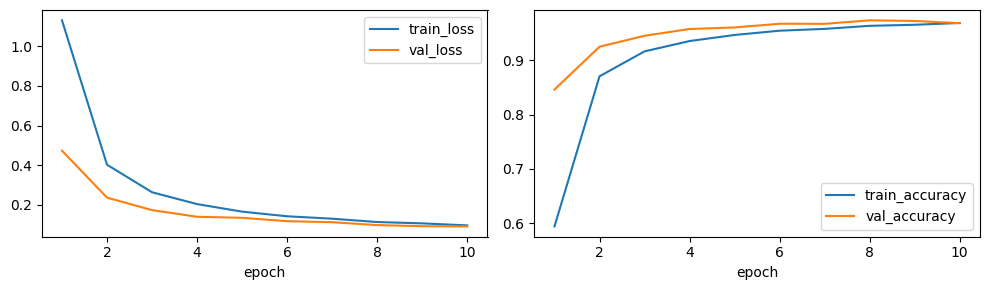

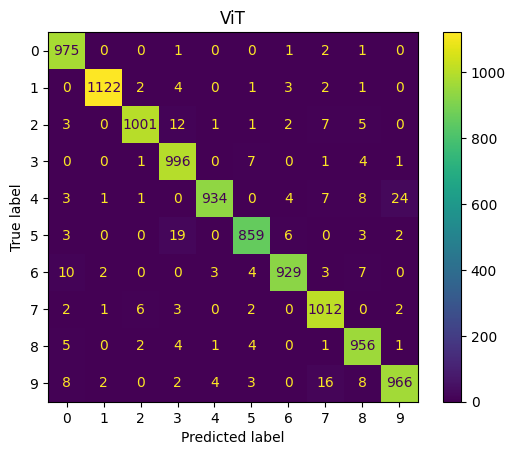

              precision    recall  f1-score   support

           0     0.9663    0.9949    0.9804       980
           1     0.9947    0.9885    0.9916      1135
           2     0.9882    0.9700    0.9790      1032
           3     0.9568    0.9861    0.9712      1010
           4     0.9905    0.9511    0.9704       982
           5     0.9750    0.9630    0.9690       892
           6     0.9831    0.9697    0.9764       958
           7     0.9629    0.9844    0.9735      1028
           8     0.9627    0.9815    0.9720       974
           9     0.9699    0.9574    0.9636      1009

    accuracy                         0.9750     10000
   macro avg     0.9750    0.9747    0.9747     10000
weighted avg     0.9752    0.9750    0.9750     10000



,accuracy,macro_f1,loss,model,training_seconds,loss_kind
0,0.975,0.97471,0.083976,ViT,205.403174,test cross entropy


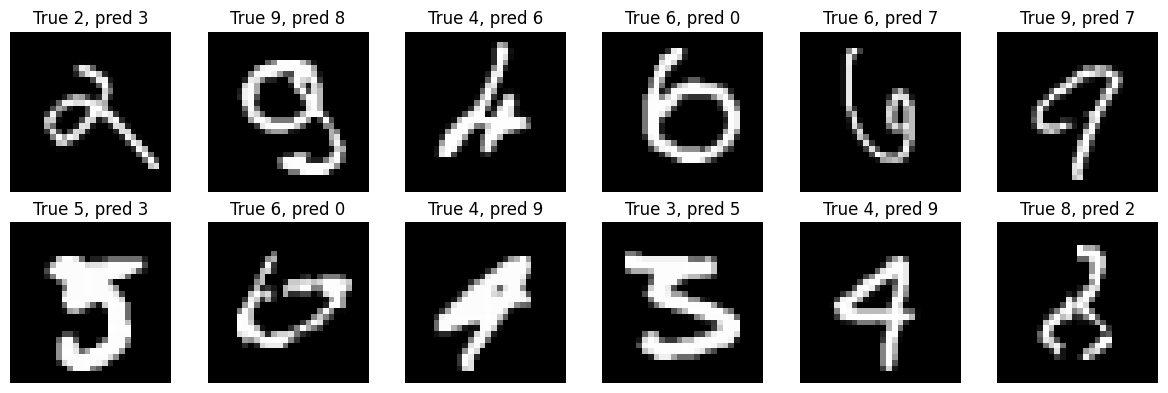

In [3]:
tf=transforms.Compose([transforms.ToTensor(),transforms.Normalize((.1307,),(.3081,))])
ls=loaders(tf)
model,row=fit(model,'ViT',ls,lr=1e-3)
vit_table=pd.DataFrame([row]); display(vit_table)
vit_table.to_csv(OUT/'part2_results.csv',index=False)
model.eval(); errors=[]
with torch.inference_mode():
    for x,y in ls[2]:
        pred=model(x.to(device)).argmax(1).cpu()
        for i in (pred!=y).nonzero().flatten().tolist():
            errors.append((x[i],int(y[i]),int(pred[i])))
        if len(errors)>=12: break
if errors:
    fig,axs=plt.subplots(2,6,figsize=(12,4))
    for ax,item in zip(axs.flat,errors[:12]):
        x,y,p=item; ax.imshow(x[0]*.3081+.1307,cmap='gray'); ax.set_title(f'True {y}, pred {p}'); ax.axis('off')
    for ax in list(axs.flat)[min(12,len(errors)):]: ax.axis('off')
    plt.tight_layout(); plt.savefig(OUT/'ViT_errors.png'); plt.show()


## 3. Compare with Part 1
Upload both `part1_results.csv` and `config.json` from the Part 1 output ZIP. Cancel/skip this cell if Part 1 has not run yet; the ViT notebook still exports its own results. Configuration is checked before combining. Run both notebooks on the same GPU type for timing comparisons. Even then session load can affect timing.

Upload Part 1 part1_results.csv AND config.json together.


Saving config.json to config.json
Saving part1_results.csv to part1_results.csv


,accuracy,macro_f1,loss,model,training_seconds,loss_kind,mean_iou,class_and_iou50
0,0.9915,0.991413,0.028509,CNN,132.575223,test cross entropy,NaN,NaN
1,0.9934,0.993396,0.021270,VGG16,3540.994566,test cross entropy,NaN,NaN
2,0.9931,0.993035,0.020648,AlexNet,1014.235394,test cross entropy,NaN,NaN
3,0.9927,0.992622,NaN,FasterRCNN,4001.537724,N/A: detector objective,0.943441,0.9924
4,0.9750,0.974710,0.083976,ViT,205.403174,test cross entropy,NaN,NaN


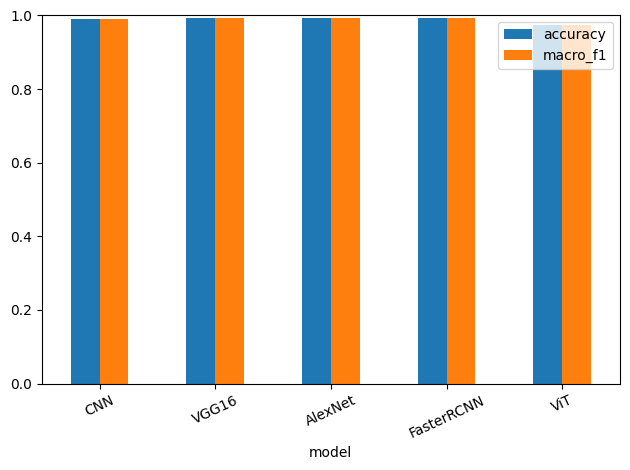

Best measured accuracy: VGG16


In [4]:
from google.colab import files
combined=vit_table.copy()
print('Upload Part 1 part1_results.csv AND config.json together.')
uploaded=files.upload()
if 'part1_results.csv' in uploaded and 'config.json' in uploaded:
    import io
    previous=json.loads(uploaded['config.json'])
    keys=['seed','quick','epochs','train_n','val_n','test_n']
    mismatch=[k for k in keys if previous.get(k)!=config.get(k)]
    if mismatch:
        print('Not combining incompatible runs:',mismatch)
    else:
        if previous.get('gpu')!=config['gpu']: print('WARNING: different GPU; timing is not directly comparable.')
        combined=pd.concat([pd.read_csv(io.BytesIO(uploaded['part1_results.csv'])),vit_table],ignore_index=True)
else:
    print('Part 1 comparison deferred: both files are required.')
display(combined)
combined.to_csv(OUT/'combined_results.csv',index=False)
combined.set_index('model')[['accuracy','macro_f1']].plot.bar(ylim=(0,1),rot=25)
plt.tight_layout(); plt.savefig(OUT/'combined_comparison.png'); plt.show()
print('Best measured accuracy:',combined.loc[combined.accuracy.idxmax(),'model'])


## 4. Interpret results and synthesize
Use the measured table and curves, not assumed rankings. Does ViT generalize as well as CNN with this amount of data? Does its validation loss suggest undertraining or overfitting? Which digit pairs are confused? CNN imposes locality and translation-related inductive biases; ViT learns interactions between patches. Explain how this may affect sample efficiency, without assuming CNN must always win. Compare the cost of ImageNet transfer and the unnecessary localization task in Faster R-CNN. Accuracy differences from one seed are descriptive, not evidence of statistical significance.

In [5]:
report='# MNIST computer vision lab — Part 2\n\nStudent: Saber Ben Hamda | FST Tanger\n\n'
report+='## ViT from scratch\n49 patches (4x4), embedding 64, 4 heads, 4 blocks, MLP width 128, learned positions and class token. No pretrained transformer.\n\n'
report+='Configuration: '+json.dumps(config)+'\n\n```text\n'+combined.to_string(index=False)+'\n```\n\n'
report+='## Interpretation to complete\n- Relate accuracy and macro-F1 to the confusion matrix.\n- Discuss training/validation loss and generalization.\n- Compare against Part 1, including timing and pretraining caveats.\n- Do not compare the detector composite loss to cross-entropy.\n\n'
report+='## Personal synthesis (complete)\nI learned how patch embeddings and attention ...\nThe measured tradeoff between CNN and ViT was ...\nMy next experiment would be ...\n\n'
report+='## Reproduce\nOpen each notebook in Colab, enable GPU, match QUICK/EPOCHS, run Part 1 then Part 2. Upload Part 1 CSV and config for comparison. Commit notebooks, result tables, plots and completed README to GitHub, excluding large weights and data.\n'
(OUT/'README_part2.md').write_text(report)
import shutil
shutil.make_archive('/content/part2_outputs','zip',OUT)
files.download('/content/part2_outputs.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## References
- [Assignment tutorial: Brian Pulfer, ViT from scratch](https://medium.com/mlearning-ai/vision-transformers-from-scratch-pytorch-a-step-by-step-guide-96c3313c2e0c)
- [Original ViT paper](https://arxiv.org/abs/2010.11929)
- [PyTorch MNIST](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html)